# 06 · Results: Table 3, Figure 1, Figure 2 (Results 4.1–4.2)

In [1]:
import os
from pathlib import Path
import pandas as pd
from IPython.display import display
from hpo import config, data, spaces, starts, methods, runner, stats, plots

pd.set_option("display.precision", 5)
# Results folder: the full run by default. Set HPO_RESULTS=smoke to read the smoke test.
RESULTS = (
    config.SMOKE_DIR if os.environ.get("HPO_RESULTS") == "smoke" else config.RESULTS_DIR
)
FIGS, TABLES = RESULTS / "figures", RESULTS / "tables"
TABLES.mkdir(parents=True, exist_ok=True)
print("Reading/writing:", RESULTS.relative_to(config.ROOT))

Reading/writing: results


## Table 3 · Mean ± std of best validation AUC and wall-clock time, and different settings tried (of 256 fits)

In [2]:
runs, curves = stats.load(RESULTS)
print(stats.check_runs(runs)["all_full_budget"], "= every run used the full budget")
table = stats.summary_table(runs, curves)
table.to_csv(TABLES / "table3_mean_std.csv")
table

True = every run used the full budget


auc_mean  auc_std  time_mean_s  time_std_s  seeds  \
model method                                                      
svm   grid     0.82981  0.00000    102.13416     2.23212     20   
      random   0.83002  0.00017    102.36361    11.42663     20   
      ga       0.82989  0.00026     66.18078     8.06926     20   
      de       0.83049  0.00021     67.35725     7.18339     20   
      pso      0.83058  0.00023     73.25110     8.12086     20   
rf    grid     0.83721  0.00000    206.63440     3.32068     20   
      random   0.83681  0.00027    207.11550     5.76081     20   
      ga       0.83725  0.00048    124.99317    30.86833     20   
      de       0.83758  0.00040    163.02909    34.72403     20   
      pso      0.83764  0.00053    141.21335    57.44450     20   
xgb   grid     0.83952  0.00000     52.98836     1.83784     20   
      random   0.84099  0.00103     49.85070     3.40457     20   
      ga       0.84241  0.00101     30.75457    10.26456     20   
      de       0.84241  0.00090     39.03712     9.76166     20   
      pso      0.84353  0.00120     23.50756     7.97412     20   

              distinct_settings_mean  
model method                          
svm   grid                    256.00  
      random                  256.00  
      ga                       74.30  
      de                      254.95  
      pso                     254.10  
rf    grid                    256.00  
      random                  256.00  
      ga                      122.35  
      de                      255.25  
      pso                     254.50  
xgb   grid                    256.00  
      random                  256.00  
      ga                      157.05  
      de                      255.65  
      pso                     254.75

## Figure 1 · Box plots of best validation AUC over 20 seeds

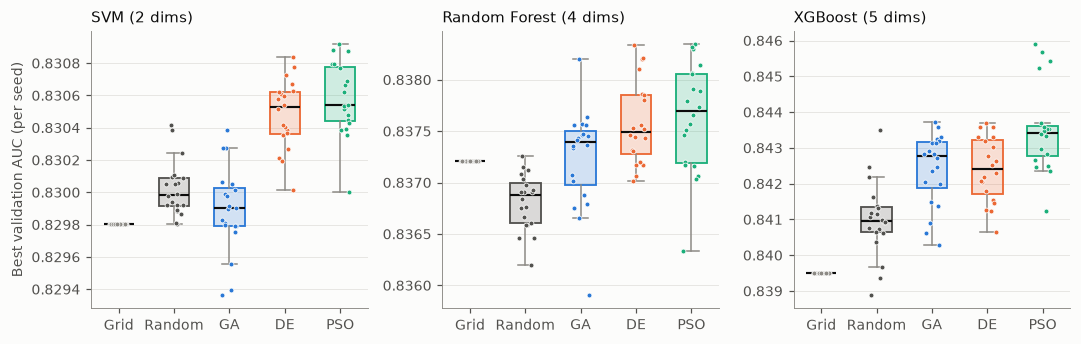

In [3]:
fig = plots.fig_boxplots(runs)
plots.save(fig, FIGS, "fig1_boxplots")

## Figure 2 · Convergence of GA, DE and PSO (mean, IQR band)
All three curves share the same best-so-far value at fit 16 (shared starts), so they diverge only through the search itself.

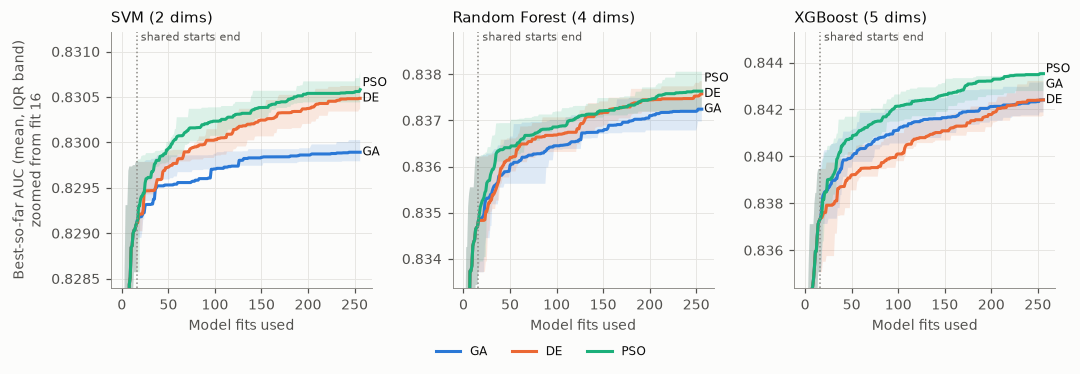

In [4]:
conv = stats.convergence(curves)
conv.to_csv(TABLES / "fig2_convergence.csv", index=False)
fig = plots.fig_convergence(conv)
plots.save(fig, FIGS, "fig2_convergence")